**Generative AI Use**: For the purposes of the assignments, the use of generative AI is subject to the same policies regarding collaboration. Just as with other collaborators, each student must write down the solutions independently of the output of the interaction and the submission should include a note denoting the nature of the collaboration. The use of generative AI tools to substantially complete sections of the assignments is not in line with the spirit of the assignments, and would be a violation of the [Honor Code](https://communitystandards.stanford.edu/policies-and-guidance/honor-code).

In [1]:
# VS Code local setup: locate the Assignment 1 project root.
from pathlib import Path
import os
import sys

search_paths = [
    Path.cwd(),
    Path.cwd() / 'Assignments' / 'Assignment1',
    Path.cwd() / 'Assignment1',
    *Path.cwd().parents,
]
PROJECT_ROOT = next(
    (path.resolve() for path in search_paths if (path / 'cs231n').is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        'Cannot find Assignment1/cs231n. Open this notebook from the CS231n '
        'workspace, then run the cell again.'
    )

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

CIFAR10_DIR = PROJECT_ROOT / 'cs231n' / 'datasets' / 'cifar-10-batches-py'
if not CIFAR10_DIR.is_dir():
    raise FileNotFoundError(
        f'CIFAR-10 dataset not found: {CIFAR10_DIR}. '
        'Download it with cs231n/datasets/get_datasets.sh first.'
    )

print(f'Project root: {PROJECT_ROOT}')
print(f'CIFAR-10 directory: {CIFAR10_DIR}')

Project root: D:\Extra Learning\CS231n\Assignments\Assignment1
CIFAR-10 directory: D:\Extra Learning\CS231n\Assignments\Assignment1\cs231n\datasets\cifar-10-batches-py


# Image features exercise
*Complete and hand in this completed worksheet (including its outputs and any supporting code outside of the worksheet) with your assignment submission. For more details see the [assignments page](http://vision.stanford.edu/teaching/cs231n/assignments.html) on the course website.*

We have seen that we can achieve reasonable performance on an image classification task by training a linear classifier on the pixels of the input image. In this exercise we will show that we can improve our classification performance by training linear classifiers not on raw pixels but on features that are computed from the raw pixels.

All of your work for this exercise will be done in this notebook.

In [2]:
import random
import numpy as np
from cs231n.data_utils import load_CIFAR10
import matplotlib.pyplot as plt


%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# for auto-reloading extenrnal modules
# see http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
%load_ext autoreload
%autoreload 2

## Load data
Similar to previous exercises, we will load CIFAR-10 data from disk.

In [3]:
from cs231n.features import color_histogram_hsv, hog_feature

def get_CIFAR10_data(num_training=49000, num_validation=1000, num_test=1000):
    # Load the raw CIFAR-10 data
    cifar10_dir = 'cs231n/datasets/cifar-10-batches-py'

    # Cleaning up variables to prevent loading data multiple times (which may cause memory issue)
    try:
       del X_train, y_train
       del X_test, y_test
       print('Clear previously loaded data.')
    except:
       pass

    X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

    # Subsample the data
    mask = list(range(num_training, num_training + num_validation))
    X_val = X_train[mask]
    y_val = y_train[mask]
    mask = list(range(num_training))
    X_train = X_train[mask]
    y_train = y_train[mask]
    mask = list(range(num_test))
    X_test = X_test[mask]
    y_test = y_test[mask]

    return X_train, y_train, X_val, y_val, X_test, y_test

X_train, y_train, X_val, y_val, X_test, y_test = get_CIFAR10_data()

D:\Extra Learning\CS231n\Assignments\Assignment1\cs231n\data_utils.py:15: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  return pickle.load(f, encoding="latin1")


## Extract Features
For each image we will compute a Histogram of Oriented
Gradients (HOG) as well as a color histogram using the hue channel in HSV
color space. We form our final feature vector for each image by concatenating
the HOG and color histogram feature vectors.

Roughly speaking, HOG should capture the texture of the image while ignoring
color information, and the color histogram represents the color of the input
image while ignoring texture. As a result, we expect that using both together
ought to work better than using either alone. Verifying this assumption would
be a good thing to try for your own interest.

The `hog_feature` and `color_histogram_hsv` functions both operate on a single
image and return a feature vector for that image. The extract_features
function takes a set of images and a list of feature functions and evaluates
each feature function on each image, storing the results in a matrix where
each column is the concatenation of all feature vectors for a single image.

In [4]:
from cs231n.features import *

# num_color_bins = 10 # Number of bins in the color histogram
num_color_bins = 25 # Number of bins in the color histogram
feature_fns = [hog_feature, lambda img: color_histogram_hsv(img, nbin=num_color_bins)]
X_train_feats = extract_features(X_train, feature_fns, verbose=True)
X_val_feats = extract_features(X_val, feature_fns)
X_test_feats = extract_features(X_test, feature_fns)

# Preprocessing: Subtract the mean feature
mean_feat = np.mean(X_train_feats, axis=0, keepdims=True)
X_train_feats -= mean_feat
X_val_feats -= mean_feat
X_test_feats -= mean_feat

# Preprocessing: Divide by standard deviation. This ensures that each feature
# has roughly the same scale.
std_feat = np.std(X_train_feats, axis=0, keepdims=True)
X_train_feats /= std_feat
X_val_feats /= std_feat
X_test_feats /= std_feat

# Preprocessing: Add a bias dimension
X_train_feats = np.hstack([X_train_feats, np.ones((X_train_feats.shape[0], 1))])
X_val_feats = np.hstack([X_val_feats, np.ones((X_val_feats.shape[0], 1))])
X_test_feats = np.hstack([X_test_feats, np.ones((X_test_feats.shape[0], 1))])

Done extracting features for 1000 / 49000 images
Done extracting features for 2000 / 49000 images
Done extracting features for 3000 / 49000 images
Done extracting features for 4000 / 49000 images
Done extracting features for 5000 / 49000 images
Done extracting features for 6000 / 49000 images
Done extracting features for 7000 / 49000 images
Done extracting features for 8000 / 49000 images
Done extracting features for 9000 / 49000 images
Done extracting features for 10000 / 49000 images
Done extracting features for 11000 / 49000 images
Done extracting features for 12000 / 49000 images
Done extracting features for 13000 / 49000 images
Done extracting features for 14000 / 49000 images
Done extracting features for 15000 / 49000 images
Done extracting features for 16000 / 49000 images
Done extracting features for 17000 / 49000 images
Done extracting features for 18000 / 49000 images
Done extracting features for 19000 / 49000 images
Done extracting features for 20000 / 49000 images
Done extr

## Train Softmax classifier on features
Using the Softmax code developed earlier in the assignment, train Softmax classifiers on top of the features extracted above; this should achieve better results than training them directly on top of raw pixels.

In [5]:
# Use the validation set to tune the learning rate and regularization strength

from cs231n.classifiers.linear_classifier import Softmax

learning_rates = [1e-7, 1e-6]
regularization_strengths = [5e5, 5e6]

results = {}
best_val = -1
best_softmax = None

################################################################################
# TODO
################################################################################

np.random.seed(231)

num_iters = 1500

for learning_rate in learning_rates:
    for regularization_strength in regularization_strengths:
        classifier = Softmax()

        classifier.train(
            X_train_feats,
            y_train,
            learning_rate=learning_rate,
            reg=regularization_strength,
            num_iters=num_iters,
            batch_size=200,
            verbose=False,
        )

        y_train_pred = classifier.predict(X_train_feats)
        train_accuracy = np.mean(y_train_pred == y_train)

        y_val_pred = classifier.predict(X_val_feats)
        val_accuracy = np.mean(y_val_pred == y_val)

        results[
            (learning_rate, regularization_strength)
        ] = (
            train_accuracy,
            val_accuracy,
        )

        if val_accuracy > best_val:
            best_val = val_accuracy
            best_softmax = classifier

# Print out results.
for lr, reg in sorted(results):
    train_accuracy, val_accuracy = results[(lr, reg)]

    print(
        "lr %e reg %e train accuracy: %f val accuracy: %f"
        % (
            lr,
            reg,
            train_accuracy,
            val_accuracy,
        )
    )

print("best validation accuracy achieved: %f" % best_val)

D:\Extra Learning\CS231n\Assignments\Assignment1\cs231n\classifiers\softmax.py:106: RuntimeWarning: overflow encountered in scalar multiply
  loss += reg * np.sum(W ** 2)
C:\Users\36027\AppData\Roaming\Python\Python313\site-packages\numpy\_core\fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
D:\Extra Learning\CS231n\Assignments\Assignment1\cs231n\classifiers\softmax.py:106: RuntimeWarning: overflow encountered in square
  loss += reg * np.sum(W ** 2)
D:\Extra Learning\CS231n\Assignments\Assignment1\cs231n\classifiers\softmax.py:131: RuntimeWarning: overflow encountered in multiply
  dW += 2.0 * reg * W
D:\Extra Learning\CS231n\Assignments\Assignment1\cs231n\classifiers\softmax.py:88: RuntimeWarning: invalid value encountered in dot
  scores = np.dot(X, W)


lr 1.000000e-07 reg 5.000000e+05 train accuracy: 0.415571 val accuracy: 0.417000
lr 1.000000e-07 reg 5.000000e+06 train accuracy: 0.317347 val accuracy: 0.300000
lr 1.000000e-06 reg 5.000000e+05 train accuracy: 0.317796 val accuracy: 0.346000
lr 1.000000e-06 reg 5.000000e+06 train accuracy: 0.100265 val accuracy: 0.087000
best validation accuracy achieved: 0.417000


In [6]:
# Evaluate your trained Softmax on the test set: you should be able to get at least 0.42
y_test_pred = best_softmax.predict(X_test_feats)
test_accuracy = np.mean(y_test == y_test_pred)
print(test_accuracy)

0.425


In [7]:
# Save best softmax model
best_softmax.save("best_softmax_features.npy")

best_softmax_features.npy saved.


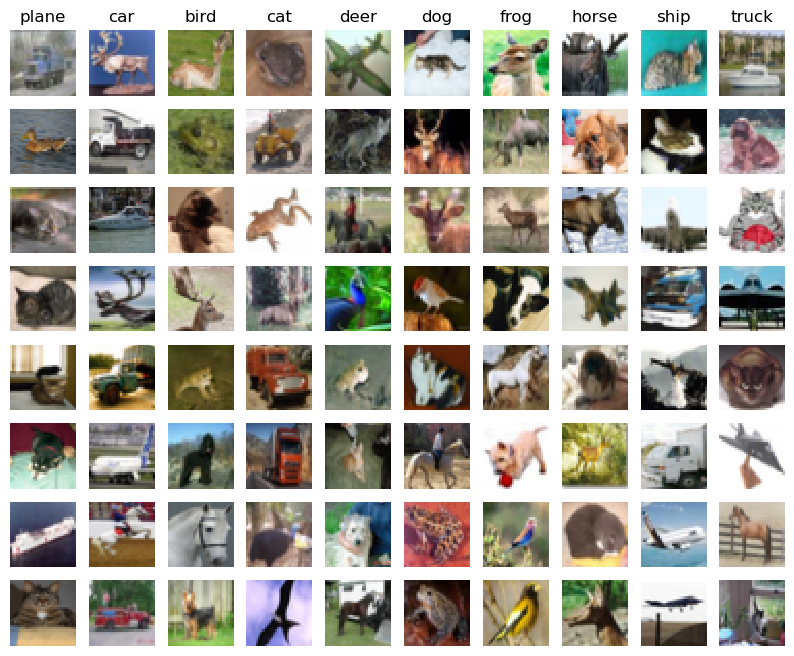

In [8]:
# An important way to gain intuition about how an algorithm works is to
# visualize the mistakes that it makes. In this visualization, we show examples
# of images that are misclassified by our current system. The first column
# shows images that our system labeled as "plane" but whose true label is
# something other than "plane".

examples_per_class = 8
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
for cls, cls_name in enumerate(classes):
    idxs = np.where((y_test != cls) & (y_test_pred == cls))[0]
    idxs = np.random.choice(idxs, examples_per_class, replace=False)
    for i, idx in enumerate(idxs):
        plt.subplot(examples_per_class, len(classes), i * len(classes) + cls + 1)
        plt.imshow(X_test[idx].astype('uint8'))
        plt.axis('off')
        if i == 0:
            plt.title(cls_name)
plt.show()

### Inline question 1:
Describe the misclassification results that you see. Do they make sense?


$\color{blue}{\textit Your Answer:}$

这些误分类结果总体上是合理的。被分到同一预测类别的图片通常与该类别具有相似的颜色、边缘方向或局部纹理。例如，猫和狗、鹿和马之间具有相似的身体轮廓和纹理；汽车和卡车之间具有相似的边缘结构；飞机、鸟和船也可能因为背景中存在大面积的天空或水面而被混淆。

产生这些错误的主要原因是当前分类器使用的 HOG 和颜色直方图只能描述图像的低层特征。HOG 可以捕捉边缘和纹理，但无法准确理解物体的整体结构；颜色直方图只统计颜色分布，忽略了颜色在图像中的具体位置。同时，Softmax 是线性分类器，不能建立复杂的非线性决策边界。因此，当不同类别具有相似的颜色、纹理或轮廓时，模型容易将它们混淆。




## Neural Network on image features
Earlier in this assigment we saw that training a two-layer neural network on raw pixels achieved better classification performance than linear classifiers on raw pixels. In this notebook we have seen that linear classifiers on image features outperform linear classifiers on raw pixels.

For completeness, we should also try training a neural network on image features. This approach should outperform all previous approaches: you should easily be able to achieve over 55% classification accuracy on the test set; our best model achieves about 60% classification accuracy.

In [9]:
# Preprocessing: Remove the bias dimension
# Make sure to run this cell only ONCE
print(X_train_feats.shape)
X_train_feats = X_train_feats[:, :-1]
X_val_feats = X_val_feats[:, :-1]
X_test_feats = X_test_feats[:, :-1]

print(X_train_feats.shape)

(49000, 170)
(49000, 169)


In [10]:
from cs231n.classifiers.fc_net import TwoLayerNet
from cs231n.solver import Solver

input_dim = X_train_feats.shape[1]
hidden_dim = 500
num_classes = 10

data = {
    'X_train': X_train_feats,
    'y_train': y_train,
    'X_val': X_val_feats,
    'y_val': y_val,
    'X_test': X_test_feats,
    'y_test': y_test,
}

net = TwoLayerNet(input_dim, hidden_dim, num_classes)
best_net = None

################################################################################
# TODO: Train a two-layer neural network on image features. You may want to    #
# cross-validate various parameters as in previous sections. Store your best   #
# model in the best_net variable.                                              #
################################################################################

np.random.seed(231)

search_configs = [
    {
        "weight_scale": 1e-2,
        "reg": 1e-3,
        "learning_rate": 1e-2,
    },
    {
        "weight_scale": 5e-2,
        "reg": 1e-3,
        "learning_rate": 1e-2,
    },
    {
        "weight_scale": 1e-1,
        "reg": 1e-3,
        "learning_rate": 1e-2,
    },
]

results = []
best_val_acc = -1.0
best_solver = None

for run_id, config in enumerate(search_configs):
    np.random.seed(231 + run_id)

    model = TwoLayerNet(
        input_dim=input_dim,
        hidden_dim=hidden_dim,
        num_classes=num_classes,
        weight_scale=config["weight_scale"],
        reg=config["reg"],
    )

    solver = Solver(
        model,
        data,
        update_rule="sgd_momentum",
        optim_config={
            "learning_rate": config["learning_rate"],
            "momentum": 0.9,
        },
        lr_decay=0.95,
        num_epochs=10,
        batch_size=200,
        print_every=200,
        verbose=False,
    )

    solver.train()

    val_acc = solver.best_val_acc

    results.append({
        "weight_scale": config["weight_scale"],
        "reg": config["reg"],
        "learning_rate": config["learning_rate"],
        "val_acc": val_acc,
    })

    print(
        f"Trial {run_id + 1}/{len(search_configs)}: "
        f"weight_scale={config['weight_scale']}, "
        f"reg={config['reg']}, "
        f"learning_rate={config['learning_rate']}, "
        f"val_acc={val_acc:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_net = solver.model
        best_solver = solver

results.sort(
    key=lambda result: result["val_acc"],
    reverse=True,
)

print("\nResults:")
for result in results:
    print(result)

print("\nBest validation accuracy:", best_val_acc)
print("Best configuration:", results[0])


Trial 1/3: weight_scale=0.01, reg=0.001, learning_rate=0.01, val_acc=0.5780
Trial 2/3: weight_scale=0.05, reg=0.001, learning_rate=0.01, val_acc=0.6030
Trial 3/3: weight_scale=0.1, reg=0.001, learning_rate=0.01, val_acc=0.5820

Results:
{'weight_scale': 0.05, 'reg': 0.001, 'learning_rate': 0.01, 'val_acc': np.float64(0.603)}
{'weight_scale': 0.1, 'reg': 0.001, 'learning_rate': 0.01, 'val_acc': np.float64(0.582)}
{'weight_scale': 0.01, 'reg': 0.001, 'learning_rate': 0.01, 'val_acc': np.float64(0.578)}

Best validation accuracy: 0.603
Best configuration: {'weight_scale': 0.05, 'reg': 0.001, 'learning_rate': 0.01, 'val_acc': np.float64(0.603)}


In [11]:
# Run your best neural net classifier on the test set. You should be able
# to get more than 58% accuracy. It is also possible to get >60% accuracy
# with careful tuning.

y_test_pred = np.argmax(best_net.loss(data['X_test']), axis=1)
test_acc = (y_test_pred == data['y_test']).mean()
print(test_acc)

0.581


In [12]:
# Save best model
best_net.save("best_two_layer_net_features.npy")

best_two_layer_net_features.npy saved.
